# Shade the Walk

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kunifujiwara/VoxCity/blob/main/docs/examples/demo_shade_the_walk.ipynb) · [All tutorials](index.md)

Build a 3D city from open map data, compute the sunlight on a walk over a whole year, then place trees to shade it.

On a hot day, being in the sun or in the shade makes a large difference to how hot a street feels. This notebook computes where the sun reaches the street, and where buildings and trees give shade.

**No coding needed.** Run the cells from top to bottom (▶ or **Shift + Enter**), set the forms, and click on the maps when asked. An orange box tells you what to do next. If nothing helps: **Runtime › Restart session**, then **Runtime › Run before**.

**If Colab times out** (after about 90 minutes idle), run **1.1** and **1.2** again and continue. In the competition, then run **8.1** and **8.5**.

| Part | What you do |
|---|---|
| **1–4** | Install, choose an area, build and look at the 3D city |
| **5–7** | Sunlight at one moment and over a year; measure a walk; one what-if change |
| **8–9** | Competition: place 10 trees to shade a walk |
| *Extra* | *Shade through the day and through the year* |

**Two questions to keep in mind**
1. On 21 June at 3 pm, which pavements are in shade, and why?
2. Over a whole year, which places get the least sunlight? What do they have in common?

## 1 · Set-up
### 1.1 Install VoxCity
Takes 1–2 minutes. Colab may then restart by itself: wait for *Connected*, then go to 1.2 (do not run 1.1 again).

In [ ]:
#@title 1.1 Install VoxCity (1–2 minutes) { display-mode: "form" }
%pip install -q voxcity
# Colab has numpy and friends loaded already. If the install changed their version, the old copy in memory
# breaks the next imports, so restart the session once (the installed packages stay).
import sys, importlib.metadata
def _changed(name):
    try:
        return name in sys.modules and getattr(sys.modules[name], "__version__", None) not in (None, importlib.metadata.version(name))
    except importlib.metadata.PackageNotFoundError:
        return False
if any(_changed(n) for n in ("numpy", "scipy", "pandas", "matplotlib", "pyproj", "shapely", "numba")):
    print("Installed. Colab now restarts the session once — this is normal.")
    print("Wait until the top right says Connected again, then continue with 1.2 (do not run 1.1 again).")
    try:
        get_ipython().kernel.do_shutdown(True)   # restart the session; installed packages stay
    except Exception:
        import os
        os.kill(os.getpid(), 9)                  # fallback: Colab then restarts the session by itself
else:
    print("Installed. Continue with 1.2.")

### 1.2 Get ready
Says **Ready** when it is done.

In [ ]:
#@title 1.2 Get ready { display-mode: "form" }
import sys, importlib.metadata
if "numpy" in sys.modules and sys.modules["numpy"].__version__ != importlib.metadata.version("numpy"):
    raise SystemExit("Colab still has the old version of a library in memory. Click Runtime › Restart session, "
                     "wait until it says Connected, then run this cell (1.2) again. Do not run 1.1 again.")
try:
    import voxcity
except ImportError:
    raise SystemExit("VoxCity is not installed in this session (Colab may have timed out or reset). Run 1.1 first, then this cell.")
import os, warnings
warnings.filterwarnings("ignore")
from IPython.display import display
OUT = os.path.join("/content" if os.path.isdir("/content") else os.getcwd(), "shade_the_walk")   # Colab, or a local Jupyter folder
os.makedirs(OUT, exist_ok=True)
try:
    from google.colab import output
    output.enable_custom_widget_manager()   # needed for the interactive maps
except ImportError:
    pass

# ---- Helper functions for this notebook (run this cell once; no need to read it) ----
import math, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from voxcity.simulator.solar import get_global_solar_irradiance_map, get_direct_solar_irradiance_map, get_diffuse_solar_irradiance_map
_SKY_CACHE = {}
from voxcity.simulator.solar.temporal import get_solar_positions_astral
from voxcity.utils.weather.epw import read_epw_for_solar_simulation
from voxcity.utils.projector import GridProjector

SUN_CMAP = "magma"


def rect_center(rect):
    """Centre (lon, lat) of a rectangle given as a list of (lon, lat) vertices."""
    lons, lats = zip(*rect)
    return float(np.mean(lons)), float(np.mean(lats))


def rect_size_m(rect):
    """Side lengths (east-west, north-south) in metres of a rectangle given as (lon, lat) vertices in SW, NW, NE, SE order."""
    from geopy.distance import distance
    sw, nw, ne, se = rect[:4]
    return distance((sw[1], sw[0]), (se[1], se[0])).m, distance((sw[1], sw[0]), (nw[1], nw[0])).m


def rect_from_center(lon, lat, width_m, height_m):
    """Rectangle (lon, lat) vertices around a centre point (SW, NW, NE, SE) — a fallback if the map widget fails."""
    from geopy.distance import distance
    north = distance(meters=height_m / 2).destination((lat, lon), bearing=0).latitude
    south = distance(meters=height_m / 2).destination((lat, lon), bearing=180).latitude
    east = distance(meters=width_m / 2).destination((south, lon), bearing=90).longitude
    west = distance(meters=width_m / 2).destination((south, lon), bearing=270).longitude
    return [(west, south), (west, north), (east, north), (east, south)]


# ---------- 4 · plan view ----------
def plot_plan(city, route=None, title="Plan view: building heights and tree canopy"):
    """2D plan: buildings coloured by height, trees in green, open ground in light grey."""
    m = city.buildings.meta.meshsize
    bh = np.asarray(city.buildings.heights, dtype=float)
    can = np.asarray(city.tree_canopy.top, dtype=float)
    ny, nx = bh.shape
    ext = [0, nx * m, 0, ny * m]
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    ax.imshow(np.zeros_like(bh), origin="lower", extent=ext, cmap=ListedColormap(["#ECEEF0"]))
    ax.imshow(np.where(can > 0, 1, np.nan), origin="lower", extent=ext, cmap=ListedColormap(["#5E9E5A"]))
    im = ax.imshow(np.where(bh > 0, bh, np.nan), origin="lower", extent=ext, cmap="YlOrBr", vmin=0)
    fig.colorbar(im, ax=ax, shrink=0.8, label="Building height (m)")
    if route is not None:
        _draw_route(ax, city, route)
    ax.set_xlabel("West → East (m)"); ax.set_ylabel("South → North (m)"); ax.set_title(title)
    plt.tight_layout(); plt.show()
    return fig


# ---------- 5 · weather and sun ----------
def weather_at(epw_path, when):
    """Sun position and EPW weather for one hour. when = 'MM-DD HH:MM:SS' (local time)."""
    df, lon, lat, tz, _ = read_epw_for_solar_simulation(epw_path)
    t = pd.to_datetime(when, format="%m-%d %H:%M:%S")
    row = df[(df.index.month == t.month) & (df.index.day == t.day) & (df.index.hour == t.hour)]
    if row.empty:
        raise ValueError(f"No EPW data for {when}")
    utc = pd.DatetimeIndex(row.index[:1] - pd.Timedelta(hours=tz)).tz_localize("UTC")  # local → UTC
    pos = get_solar_positions_astral(utc, lon, lat)
    return dict(when=when, azimuth=float(pos.iloc[0]["azimuth"]), elevation=float(pos.iloc[0]["elevation"]),
                DNI=float(row.iloc[0]["DNI"]), DHI=float(row.iloc[0]["DHI"]))


def compass(azimuth):
    """Sun direction in words (azimuth in degrees clockwise from north)."""
    names = ["north", "north-east", "east", "south-east", "south", "south-west", "west", "north-west"]
    return names[int((azimuth % 360) / 45 + 0.5) % 8]


def solar_snapshot(city, epw_path, when, view_point_height=1.5):
    """Global and direct irradiance at street level (W/m²) for one hour, plus a shade mask."""
    w = weather_at(epw_path, when)
    kw = dict(view_point_height=view_point_height, show_plot=False)
    d = get_direct_solar_irradiance_map(city, w["azimuth"], w["elevation"], w["DNI"], **kw)
    key = (id(city), view_point_height)
    if key not in _SKY_CACHE or _SKY_CACHE[key][0] is not city:  # diffuse sky part per 1 W/m² of DHI,
        _SKY_CACHE[key] = (city, get_diffuse_solar_irradiance_map(city, diffuse_irradiance=1.0, **kw))  # once per model
    g = d + w["DHI"] * _SKY_CACHE[key][1]  # same result as get_global_solar_irradiance_map
    sun_max = w["DNI"] * max(math.sin(math.radians(w["elevation"])), 0.0)  # unobstructed direct on flat ground
    shade = np.where(np.isnan(d), np.nan, (d < 0.5 * sun_max).astype(float)) if sun_max > 0 else np.where(np.isnan(d), np.nan, 1.0)
    return dict(w, global_map=g, direct_map=d, shade=shade)


def plot_maps(maps, titles, label="W/m²", vmax=None, cmap=SUN_CMAP, city=None, route=None, suptitle=None, vmin=0,
              trees=None, ncols=None, crop=None):
    """Maps with one shared colour scale (buildings shown in grey). trees: cells (i, j) to mark with dots, one list per
    map or one list for all; ncols: maps per row; crop: (i0, i1, j0, j1) cells to zoom into."""
    n = len(maps)
    ncols = ncols or n
    nrows = math.ceil(n / ncols)
    vmax = vmax if vmax is not None else max(np.nanmax(a) for a in maps)
    aspect = 1.0 if crop is None else (crop[1] - crop[0]) / max(crop[3] - crop[2], 1)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, max(3.2, 5.6 * aspect) * nrows), squeeze=False)
    cm = plt.get_cmap(cmap).copy(); cm.set_bad("#9AA3AD")
    if trees is not None and (len(trees) == 0 or not isinstance(trees[0], list)):
        trees = [trees] * n
    for k, ax in enumerate(axes.flat):
        if k >= n:
            ax.axis("off"); continue
        im = ax.imshow(maps[k], origin="lower", cmap=cm, vmin=vmin, vmax=vmax)
        ax.set_title(titles[k], fontsize=12); ax.set_xticks([]); ax.set_yticks([])
        if city is not None and route is not None:
            _draw_route(ax, city, route, in_cells=True)
        if trees is not None and trees[k]:
            ax.plot([j for i, j in trees[k]], [i for i, j in trees[k]], "o", ms=7, mfc="none", mec="#15803D", mew=1.6)
        if crop is not None:
            ax.set_ylim(crop[0] - 0.5, crop[1] + 0.5); ax.set_xlim(crop[2] - 0.5, crop[3] + 0.5)
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, label=label)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    plt.show()
    return fig


# ---------- 6 · what if? ----------
def quick_change(city, choice, size_m=100, tower_m=60):
    """Scripted what-if edits that need no map. Returns a new city (the original is unchanged)."""
    from voxcity.generator import update_voxcity
    m = city.buildings.meta.meshsize
    h = np.array(city.buildings.heights, dtype=float, copy=True)
    ids = np.array(city.buildings.ids, copy=True)
    mins = np.array(city.buildings.min_heights, dtype=object, copy=True)
    top = np.array(city.tree_canopy.top, dtype=float, copy=True)
    bot = np.array(city.tree_canopy.bottom if city.tree_canopy.bottom is not None else top * 0.3, dtype=float, copy=True)
    ny, nx = h.shape
    half = int(size_m / m / 2)
    ci, cj = ny // 2, nx // 2
    if choice.startswith("Remove the tallest"):
        bid = ids[np.unravel_index(np.nanargmax(h), h.shape)]
        sel = ids == bid
        h[sel] = 0; ids[sel] = 0
        for i, j in zip(*np.where(sel)):
            mins[i, j] = []
        return update_voxcity(city, building_heights=h, building_min_heights=mins, building_ids=ids)
    if choice.startswith("Add a"):
        k = max(int(30 / m / 2), 1)
        sel = np.zeros_like(h, dtype=bool); sel[ci - k:ci + k, cj - k:cj + k] = True
        sel &= h <= 0
        h[sel] = tower_m; ids[sel] = int(np.max(ids)) + 1
        for i, j in zip(*np.where(sel)):
            mins[i, j] = [[0.0, float(tower_m)]]
        return update_voxcity(city, building_heights=h, building_min_heights=mins, building_ids=ids)
    if choice.startswith("Remove all trees"):
        return update_voxcity(city, canopy_top=np.zeros_like(top), canopy_bottom=np.zeros_like(bot))
    if choice.startswith("Plant"):
        sel = np.zeros_like(h, dtype=bool); sel[ci - half:ci + half, cj - half:cj + half] = True
        sel &= h <= 0
        top[sel] = np.maximum(top[sel], 10.0); bot[sel] = 3.0
        return update_voxcity(city, canopy_top=top, canopy_bottom=bot)
    raise ValueError("Unknown choice: " + choice)


# ---------- a typical year ----------
KEY = "sunlight on the walk (kWh/m² a year)"


def yearly_map(city, epw_path, view_point_height=1.5):
    """Sunlight at walking height added up over a typical year (kWh/m²), every day 05:00–20:00.
    Uses VoxCity's sky-patch method: the year's sun positions are grouped into 145 sky patches, so it takes seconds."""
    from voxcity.simulator.solar import get_cumulative_global_solar_irradiance
    df, lon, lat, tz, _ = read_epw_for_solar_simulation(epw_path)
    with _quiet():
        wh = get_cumulative_global_solar_irradiance(city, df, lon, lat, tz, start_time="01-01 05:00:00", end_time="12-31 20:00:00",
                                                    use_sky_patches=True, sky_discretization="tregenza", show_plot=False,
                                                    view_point_height=view_point_height)
    return wh / 1000.0


def open_ground(ymap):
    """The sunniest open spot of the map: the reference for 'compared with open ground'."""
    return float(np.nanmax(ymap))


def route_year(city, route, ymap, name="baseline", n_trees=None, threshold=0.5):
    """Sunlight numbers for the walk over a typical year (cells inside buildings are skipped).
    'well shaded' = a cell that gets less than `threshold` x the sunlight of the sunniest open spot."""
    m = city.buildings.meta.meshsize
    cells = [c for c in route_cells(city, route) if not np.isnan(ymap[c])]
    v = np.array([ymap[c] for c in cells], dtype=float)
    ref = open_ground(ymap)
    shaded = v < threshold * ref
    run = best = 0
    for s in shaded:                     # longest unbroken stretch that is not well shaded
        run = 0 if s else run + 1
        best = max(best, run)
    mean = float(v.mean()) if len(v) else float("nan")
    out = {"scenario": name, "route length (m)": round(len(cells) * m), KEY: round(mean),
           "compared with open ground (%)": round(100 * mean / ref), "well shaded (%)": round(100 * float(shaded.mean())) if len(v) else 0,
           "longest sunny stretch (m)": round(best * m)}
    if n_trees is not None:
        out["trees used"] = int(n_trees)
    return out


def compare_year(before, after, label="What if"):
    """Numbers and maps for a typical year, before and after an edit (cells open in both)."""
    ok = ~np.isnan(before) & ~np.isnan(after)
    m0, m1 = float(np.nanmean(before[ok])), float(np.nanmean(after[ok]))
    diff = np.where(ok, after - before, np.nan)
    print(f"Average sunlight on open ground over a year: {m0:.0f} → {m1:.0f} kWh/m²  ({100 * (m1 - m0) / m0:+.1f}%)")
    big = diff[np.unravel_index(np.nanargmax(np.abs(np.nan_to_num(diff))), diff.shape)]
    print(f"Largest change in one cell: {big:+.0f} kWh/m² a year")
    vmax = max(np.nanmax(before), np.nanmax(after))
    plot_maps([before, after], ["Before", label], label="kWh/m² a year", vmax=vmax)
    lim = np.nanmax(np.abs(diff)) or 1
    return plot_maps([diff], [f"Change: {label} − before (blue = less sun)"], label="Δ kWh/m² a year", vmin=-lim, vmax=lim, cmap="RdBu_r")


def route_text(route):
    return "; ".join(f"{lo:.5f},{la:.5f}" for lo, la in route)


def demo_tree_table(route, n, top=10.0, bottom=3.0, crown=8.0, side_m=4.0):
    """n trees spaced along the walk, a few metres to its left-hand side (for the offline test and demonstrations)."""
    import geopandas as gpd
    from shapely.geometry import Point
    segs = list(zip(route[:-1], route[1:]))
    lengths = [math.hypot((b[0] - a[0]) * 111320 * math.cos(math.radians(a[1])), (b[1] - a[1]) * 111320) for a, b in segs]
    total = sum(lengths)
    pts = []
    for k in range(n):
        d = total * (k + 0.5) / n
        for idx, ((a, b), L) in enumerate(zip(segs, lengths)):
            if d <= L or idx == len(segs) - 1:
                t = min(d / L, 1.0) if L else 0.0
                lo, la = a[0] + t * (b[0] - a[0]), a[1] + t * (b[1] - a[1])
                nx_, ny_ = -(b[1] - a[1]), (b[0] - a[0])            # left-hand normal, in degrees
                norm = math.hypot(nx_ * 111320 * math.cos(math.radians(la)), ny_ * 111320) or 1.0
                pts.append(Point(lo + nx_ / norm * side_m, la + ny_ / norm * side_m))
                break
            d -= L
    return gpd.GeoDataFrame({"tree_id": list(range(100001, 100001 + len(pts))), "top_height": top, "bottom_height": bottom,
                             "crown_diameter": crown}, geometry=pts, crs="EPSG:4326")


# ---------- 6 · the walk ----------
def route_cells(city, route, step_m=None):
    """Grid cells (i, j) along a polyline of (lon, lat) points, sampled every half cell."""
    pj = GridProjector.from_city(city)
    m = city.buildings.meta.meshsize
    step_m = step_m or m / 2
    ny, nx = city.buildings.heights.shape
    pts = []
    for (lo0, la0), (lo1, la1) in zip(route[:-1], route[1:]):
        seg = math.hypot((lo1 - lo0) * 111320 * math.cos(math.radians(la0)), (la1 - la0) * 111320)
        k = max(int(seg / step_m), 1)
        for t in np.linspace(0, 1, k, endpoint=False):
            pts.append((lo0 + t * (lo1 - lo0), la0 + t * (la1 - la0)))
    pts.append(route[-1])
    cells, seen = [], set()
    for lo, la in pts:
        i, j = pj.lon_lat_to_cell(lo, la)
        if 0 <= i < ny and 0 <= j < nx and (i, j) not in seen:
            seen.add((i, j)); cells.append((i, j))
    return cells


def _draw_route(ax, city, route, in_cells=False):
    m = 1.0 if in_cells else city.buildings.meta.meshsize
    pj = GridProjector.from_city(city)
    ij = [pj.lon_lat_to_cell(lo, la) for lo, la in route]
    xs = [(j + 0.5) * m for i, j in ij]; ys = [(i + 0.5) * m for i, j in ij]
    if in_cells:
        xs = [x - 0.5 for x in xs]; ys = [y - 0.5 for y in ys]
    ax.plot(xs, ys, color="#2DD4BF", lw=1.6, ls=(0, (4, 3)) if in_cells else "-", alpha=0.95)
    ax.plot(xs[0], ys[0], "o", ms=9, color="#0F4C5C", mec="#2DD4BF", mew=2)
    ax.plot(xs[-1], ys[-1], "s", ms=9, color="#0F4C5C", mec="#2DD4BF", mew=2)


def draw_route(center, zoom=17, area=None):
    """Map for drawing the walk, with the study area outlined. Use the polyline tool; the last line you draw is kept."""
    from ipyleaflet import Map, DrawControl, TileLayer, Polygon
    # openstreetmap.org returns "Access blocked" (403) tiles to Colab, so use Esri's key-free street map
    esri = TileLayer(url="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
                     attribution="Tiles &copy; Esri &mdash; Esri, HERE, Garmin, OpenStreetMap contributors",
                     name="Esri Street Map", max_zoom=19)
    if area:                                        # zoom so the whole area (also when rotated) fits in the 600 px high map
        lons, lats = zip(*area)
        w = (max(lons) - min(lons)) * 111320 * math.cos(math.radians(center[1]))
        h = (max(lats) - min(lats)) * 111320
        mpp = 1.2 * max(w, h) / 600                 # metres per pixel needed, with a margin
        zoom = max(12, min(18, int(math.log2(156543 * math.cos(math.radians(center[1])) / mpp))))
    m = Map(center=(center[1], center[0]), zoom=zoom, scroll_wheel_zoom=True, basemap=esri,
            layout={"height": "600px"})
    if area:                                        # outline of the study area: draw the walk inside it
        m.add(Polygon(locations=[(la, lo) for lo, la in area], color="#0F4C5C", weight=3, dash_array="8 6",
                      fill=False, name="Study area"))
    dc = DrawControl(polyline={"shapeOptions": {"color": "#C2410C", "weight": 5}},
                     polygon={}, rectangle={}, circle={}, circlemarker={}, marker={})
    store = []

    def _on(target, action, geo_json):
        if geo_json["geometry"]["type"] == "LineString":
            store.clear(); store.extend([tuple(p) for p in geo_json["geometry"]["coordinates"]])
            print(f"Route saved: {len(store)} points")
    dc.on_draw(_on); m.add(dc)
    return m, store


# ---------- offline back-up: a synthetic district ----------
def build_demo_city(meshsize=5.0, origin=(55.4190, 25.1260), size_m=500):
    """Synthetic Dubai-like test district for when the internet is unavailable. Returns (city, route)."""
    from voxcity.generator.voxelizer import Voxelizer
    from voxcity.generator.pipeline import VoxCityPipeline
    n = int(size_m / meshsize); lon0, lat0 = origin
    kx = 111320.0 * math.cos(math.radians(lat0))
    rect = [(lon0, lat0), (lon0, lat0 + size_m / 111320.0), (lon0 + size_m / kx, lat0 + size_m / 111320.0), (lon0 + size_m / kx, lat0)]
    lc = np.full((n, n), 10, dtype=np.int32); bh = np.zeros((n, n)); bid = np.zeros((n, n), dtype=np.int32); can = np.zeros((n, n))
    lc[46:53, :] = 11; lc[:, 28:33] = 11; lc[:, 66:70] = 11          # avenue (E–W) and two streets (N–S)
    rng = np.random.default_rng(7); k = 0
    for i0, i1 in [(4, 20), (24, 42), (57, 74), (78, 96)]:
        for j0, j1 in [(3, 25), (36, 63), (73, 97)]:
            if i0 >= 57 and j0 >= 73:
                continue                                              # park block
            k += 1; h = float(rng.choice([18, 24, 30, 36, 45]))
            h = 120.0 if (i0, j0) == (24, 36) else 90.0 if (i0, j0) == (57, 3) else h
            jm = (j0 + j1) // 2
            for a, b in [(j0, jm - 1), (jm + 1, j1)]:
                bh[i0:i1, a:b] = h if a == j0 else max(12.0, h - 12.0); bid[i0:i1, a:b] = k * 10 + (a != j0); lc[i0:i1, a:b] = 12
    lc[57:96, 73:97] = 1
    ii, jj = np.mgrid[0:n, 0:n]
    for _ in range(26):                                               # park trees: round crowns 10–15 m
        ci, cj, r = rng.uniform(59, 94), rng.uniform(75, 95), rng.uniform(1.0, 1.5)
        disc = ((ii - ci) ** 2 + (jj - cj) ** 2 <= r * r) & (lc == 1)
        can[disc] = np.maximum(can[disc], rng.uniform(7, 11))
    for j in range(4, 26, 3):
        can[53:55, j:j + 2] = 8.0
    bmin = np.empty((n, n), dtype=object)
    for i in range(n):
        for j in range(n):
            bmin[i, j] = [[0.0, bh[i, j]]] if bh[i, j] > 0 else []
    dem = np.zeros((n, n))
    vox = Voxelizer(voxel_size=meshsize, land_cover_source="OpenStreetMap").generate_combined(
        building_height_grid_ori=bh, building_min_height_grid_ori=bmin, building_id_grid_ori=bid,
        land_cover_grid_ori=lc, dem_grid_ori=dem, tree_grid_ori=can, canopy_bottom_height_grid_ori=can * 0.3,
        print_class_info=False)
    city = VoxCityPipeline(meshsize, rect).assemble_voxcity(
        voxcity_grid=vox, building_height_grid=bh, building_min_height_grid=bmin, building_id_grid=bid,
        land_cover_grid=lc, dem_grid=dem, canopy_height_top=can, canopy_height_bottom=can * 0.3,
        extras={"land_cover_source": "OpenStreetMap", "demo": True, "rectangle_vertices": rect})
    cell = lambda i, j: (lon0 + (j + 0.5) * meshsize / kx, lat0 + (i + 0.5) * meshsize / 111320.0)
    route = [cell(2, 34), cell(44, 34), cell(55, 34), cell(55, 64), cell(55, 72), cell(90, 71)]
    return city, route, rect


# ---------- Extra · only if time allows ----------
def sun_through_day(city, epw_path, date="06-21", hours=range(6, 20)):
    """Hour-by-hour shade and sunlight for one date. Returns (table, {hour: map})."""
    rows, maps = [], {}
    for h in hours:
        w = weather_at(epw_path, f"{date} {h:02d}:00:00")
        if w["elevation"] <= 2:
            continue
        snap = solar_snapshot(city, epw_path, f"{date} {h:02d}:00:00")
        maps[h] = snap["global_map"]
        rows.append({"date": date, "hour": h, "sun elevation (°)": round(w["elevation"], 1),
                     "sun azimuth (°)": round(w["azimuth"], 1),
                     "shaded open ground (%)": round(100 * np.nanmean(snap["shade"]), 1),
                     "mean irradiance (W/m²)": round(float(np.nanmean(snap["global_map"])))})
    return pd.DataFrame(rows), maps


def plot_day_curves(tables, labels):
    """Open ground in shade, hour by hour (solid), with the sun's elevation (dashed) for each date."""
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    ax2 = ax.twinx()
    for t, lab, c in zip(tables, labels, ["#C2410C", "#0F4C5C", "#2B7A78", "#F2994A"]):
        ax.plot(t["hour"], t["shaded open ground (%)"], "-o", color=c, lw=2.5, ms=5, label=f"{lab} · shade")
        ax2.plot(t["hour"], t["sun elevation (°)"], "--", color=c, lw=1.4, alpha=0.6, label=f"{lab} · sun height")
    ax.set_xlabel("Local time (hour)"); ax.set_ylabel("Open ground in shade (%)"); ax.set_ylim(0, 100)
    ax2.set_ylabel("Sun elevation (°), dashed"); ax2.set_ylim(0, 90)
    ax.grid(alpha=0.3); ax.set_xticks(range(6, 20, 2))
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9, loc="upper center", ncol=2)
    ax.spines["top"].set_visible(False); ax2.spines["top"].set_visible(False)
    plt.tight_layout(); plt.show()
    return fig


def describe_day(t):
    """One-line finding for a sun_through_day table (09:00–18:00)."""
    d = t[(t["hour"] >= 9) & (t["hour"] <= 18)]
    lo, hi = d.loc[d["shaded open ground (%)"].idxmin()], d.loc[d["shaded open ground (%)"].idxmax()]
    return (f"{t['date'].iloc[0]}: least shade at {int(lo['hour']):02d}:00 ({lo['shaded open ground (%)']:.0f}%, sun {lo['sun elevation (°)']:.0f}° high); "
            f"most shade at {int(hi['hour']):02d}:00 ({hi['shaded open ground (%)']:.0f}%, sun {hi['sun elevation (°)']:.0f}°).")


def year_at_time(city, epw_path, time="15:00:00", day=21):
    """Shade of open ground at one time of day, on the same day of every month."""
    rows = []
    for mth in range(1, 13):
        when = f"{mth:02d}-{day:02d} {time}"
        w = weather_at(epw_path, when)
        snap = solar_snapshot(city, epw_path, when) if w["elevation"] > 2 else None
        rows.append({"month": mth, "sun elevation (°)": round(w["elevation"], 1),
                     "shaded open ground (%)": round(100 * np.nanmean(snap["shade"]), 1) if snap else 100.0})
    return pd.DataFrame(rows)


def plot_year(t, time_label):
    months = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    ax2 = ax.twinx()
    ax.plot(t["month"], t["shaded open ground (%)"], "-o", color="#0F4C5C", lw=2.5, ms=5, label="Open ground in shade")
    ax2.plot(t["month"], t["sun elevation (°)"], "--", color="#C2410C", lw=1.5, label="Sun elevation")
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(months); ax.set_xlabel(f"Month (21st, {time_label})")
    ax.set_ylabel("Open ground in shade (%)"); ax.set_ylim(0, 100); ax2.set_ylabel("Sun elevation (°), dashed"); ax2.set_ylim(0, 90)
    ax.grid(alpha=0.3)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper center")
    ax.spines["top"].set_visible(False); ax2.spines["top"].set_visible(False)
    plt.tight_layout(); plt.show()
    return fig


# ---------- notebook steps: each visible cell calls one of these ----------
# Results are kept in STATE, so a failed or skipped step never wipes what earlier steps made.
# Problems are shown as a plain sentence that says what to do, never as a Python traceback.
import contextlib, functools, io, logging
import IPython.display as _ipd

STATE = globals().get("STATE") or {}
TEST_MODE = bool(os.environ.get("SHADE_WALK_TEST"))   # the offline test sees real errors


class Stop(Exception):
    """A plain-language message for the user, shown instead of an error."""


def _box(html, kind="warn"):
    if TEST_MODE:
        print(re.sub(r"<[^>]+>", "", html.replace("<br>", " "))); return
    bg, fg = {"warn": ("#FFF4E5", "#C2410C"), "ok": ("#E8F5EC", "#2F7D4F")}[kind]
    _ipd.display(_ipd.HTML(f'<div style="background:{bg};border-left:5px solid {fg};padding:10px 14px;margin:6px 0;'
                           f'font-size:15px;line-height:1.45;color:#1B2A2F">{html}</div>'))


def _need(key, message):
    if STATE.get(key) is None or (isinstance(STATE.get(key), list) and not STATE[key]):
        raise Stop(message)
    return STATE[key]


def step(fn):
    @functools.wraps(fn)
    def run(*args, **kwargs):
        try:
            return fn(*args, **kwargs)
        except Stop as e:
            if TEST_MODE: raise
            _box("⚠ " + str(e))
        except Exception as e:
            if TEST_MODE: raise
            _box(f"⚠ Something went wrong in this step <small>({type(e).__name__}: {str(e)[:200]})</small>.<br>"
                 "Try <b>Runtime › Restart session</b>, then <b>Runtime › Run before</b> to run all the cells above again. "
                 "If it happens again, run 1.1 and 1.2 again.")
    return run


@contextlib.contextmanager
def _quiet():
    """Hide the long technical log of downloads and model updates."""
    buf = io.StringIO()
    logging.disable(logging.INFO)
    try:
        with contextlib.redirect_stdout(buf), contextlib.redirect_stderr(buf):
            yield buf
    finally:
        logging.disable(logging.NOTSET)


NEED_AREA = "First draw your study area: run <b>2.1</b>, click <b>Fixed</b> in the panel on the map, then click the centre of your street."
NEED_CITY = "First build the city: run <b>3.1</b> and wait for “Done”."
NEED_YEAR = "First compute the sunlight over a year: run <b>5.2</b>."
NO_CHANGE = ("The map shows no change. Did you press <b>+ Add</b> after placing trees or drawing a building? "
             "Make the change on the map again, then run this cell again.")


def _note(text):
    """A small grey line of extra information."""
    if TEST_MODE:
        print(text); return
    _ipd.display(_ipd.HTML(f'<div style="color:#6B7280;font-size:12px;margin:4px 0">{text}</div>'))
MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]


def _mmdd(date):
    """'21 June', '06-21' or '2026-06-21' -> '06-21' (the weather is a typical year, so there is no year)."""
    import calendar
    d = str(date).strip()
    try:
        if len(d) == 10 and d[4] == "-":
            m, day = int(d[5:7]), int(d[8:10])
        elif len(d) == 5 and d[2] == "-":
            m, day = int(d[:2]), int(d[3:])
        else:
            day, name = d.split()
            m, day = MONTHS.index(name.capitalize()) + 1, int(day)
    except Exception:
        raise Stop(f"“{date}” is not a date the model understands. Choose a month and a day in the form.")
    if (m, day) == (2, 29):
        raise Stop("The weather file has no 29 February (it is a typical year). Choose another day.")
    day = min(day, calendar.monthrange(2025, m)[1])   # e.g. 31 June -> 30 June
    return f"{m:02d}-{day:02d}"


def _day_label(mmdd):
    return f"{int(mmdd[3:])} {MONTHS[int(mmdd[:2]) - 1]}"


@step
def choose_area(city_name, width_m, height_m):
    from voxcity.geoprocessor.draw import create_rectangle_map
    try:
        area_map, vertices = create_rectangle_map(city_name, zoom=15, width=width_m, height=height_m)
    except Exception:
        raise Stop(f"Could not find “{city_name}” on the map. Check the spelling, or type a larger nearby city, and run the cell again.")
    STATE["area"] = vertices          # filled in when you click on the map
    display(area_map)


@step
def build_city(cell_size_m=5, practice=""):
    from voxcity.generator import get_voxcity, load_voxcity, save_voxcity
    STATE["demo_route"] = None
    if practice == "demo":            # hidden switch for the offline test: no download
        city, STATE["demo_route"], area = build_demo_city(meshsize=cell_size_m)
        print("Using the practice district (made-up buildings, no download).")
    else:
        area = _need("area", NEED_AREA)
        w, h = rect_size_m(area)
        print(f"Downloading open data for your {w:.0f} m × {h:.0f} m area. This takes 1–5 minutes…")
        with _quiet():
            city = get_voxcity(area, cell_size_m, output_dir=OUT)
    with _quiet():
        save_voxcity(os.path.join(OUT, "baseline.h5"), city)
    rebuilt = STATE.get("city") is not None
    built = [tuple(v) for v in area]                  # a copy: the map in 2.1 keeps changing `area` when clicked
    if built != STATE.get("built_area"):              # a new place: the walk drawn for the old one no longer fits
        STATE.update(route=None, route_drawn=None)
    # results of the old model do not fit the new one: compute them again from 5.1
    STATE.update(city=city, area=area, built_area=built, center=rect_center(area), city_new=None, results=[],
                 jun=None, year=None, whatif_edits=None)
    m = city.buildings.meta.meshsize
    ny, nx, nz = city.voxels.classes.shape
    names = {"building_source": "buildings", "land_cover_source": "land cover", "canopy_height_source": "trees", "dem_source": "terrain"}
    used = [f"{label}: {city.extras[k]}" for k, label in names.items() if city.extras.get(k)]
    _box(f"<b>Done.</b> Your city is {nx * m:.0f} m × {ny * m:.0f} m, in cubes of {m:g} m."
         + (f"<br>Data used — {'; '.join(used)}." if used else "")
         + ("<br><b>New model:</b> run 4.1 and the steps after it again to see it." if rebuilt else ""), "ok")


@step
def show_3d():
    from voxcity.visualizer import visualize_voxcity
    visualize_voxcity(_need("city", NEED_CITY), mode="interactive", downsample=1)   # every cube, also at small sizes


def _weather(center=None):
    """The weather file of the nearest station; downloaded quietly the first time it is needed (once per area)."""
    from voxcity.utils.weather import get_nearest_epw_from_climate_onebuilding
    if STATE.get("epw") is not None:                      # one file for everything (the offline test)
        return STATE["epw"]
    lon, lat = center or _need("center", NEED_CITY)
    key = (round(lon, 1), round(lat, 1))
    files = STATE.setdefault("epw_files", {})
    if key not in files:
        with _quiet():
            epw, _, meta = get_nearest_epw_from_climate_onebuilding(lon, lat, output_dir=OUT)
        loc = meta.get("LOCATION", {}) if isinstance(meta, dict) else {}
        print("Weather from the nearest station:", str(loc.get("City", os.path.basename(epw))).replace(".", " "))
        files[key] = epw
    return files[key]


@step
def sunlight(date="2026-06-21", hour=15):
    city = _need("city", NEED_CITY)
    epw = _weather()
    mmdd, hour = _mmdd(date), int(hour)
    when, label = f"{mmdd} {hour:02d}:00:00", f"{_day_label(mmdd)}, {hour:02d}:00"
    try:
        snap = solar_snapshot(city, epw, when)
    except ValueError:
        raise Stop(f"The weather file has no data for {label}. Choose another day or hour.")
    if snap["elevation"] <= 0:
        raise Stop(f"The sun is below the horizon at {label}. Choose a time during the day.")
    print(f"{label}: the sun is {snap['elevation']:.0f}° high, in the {compass(snap['azimuth'])} · "
          f"open ground in shade: {100 * np.nanmean(snap['shade']):.0f}%")
    fig = plot_maps([snap["global_map"]], [label], label="Sunlight at 1.5 m (W/m²)")
    fig.savefig(os.path.join(OUT, "sunlight_moment.png"), dpi=150, bbox_inches="tight")
    STATE.update(jun=snap, when=when, label=label)


@step
def yearly():
    city = _need("city", NEED_CITY)
    epw = _weather()
    print("Adding up the sunlight of every daytime hour of a typical year (a few seconds)…")
    ymap = yearly_map(city, epw)
    STATE["year"] = ymap
    ref, avg = open_ground(ymap), float(np.nanmean(ymap))
    print(f"Over a year, the sunniest open spot gets {ref:.0f} kWh/m². The average open cell gets {avg:.0f} kWh/m², "
          f"{100 * avg / ref:.0f}% of that: the rest is shade from buildings and trees.")
    fig = plot_maps([ymap], ["Sunlight over a typical year"], label="kWh/m² a year, at 1.5 m")
    fig.savefig(os.path.join(OUT, "sunlight_year.png"), dpi=150, bbox_inches="tight")


def _show_walk(m, route):
    """Draw the walk as a teal line on an editor map (the editors themselves do not know about it)."""
    from ipyleaflet import Polyline
    if route and len(route) >= 2:
        m.add(Polyline(locations=[(la, lo) for lo, la in route], color="#2DD4BF", weight=6, opacity=0.95, fill=False, name="walk"))
        print("The teal line is your walk.")


def _tree_counter(m, comp):
    """A badge on the editor map that counts the placed trees after every click, and bright markers for
    those trees (the editor draws them in the same green as the city's own canopy)."""
    from ipywidgets import HTML
    from ipyleaflet import WidgetControl, Circle
    need, radius = comp["rules"]["n"], max(int(round(comp["rules"]["crown"] / 2)), 1)
    badge = HTML()

    def update(**kwargs):
        if kwargs and kwargs.get("type") not in ("click", "dblclick"):
            return
        new = _new_trees(comp)
        mine = {(round(g.y, 7), round(g.x, 7)) for g in new.geometry}
        for layer in m.layers:
            if isinstance(layer, Circle) and (round(layer.location[0], 7), round(layer.location[1], 7)) in mine                     and layer.fill_color != "#FFE600":
                layer.radius, layer.color, layer.weight = radius, "#E8112D", 3
                layer.fill_color, layer.fill_opacity = "#FFE600", 0.85
        n = len(new)
        if n < need:
            text, bg = f"Trees placed: <b>{n} of {need}</b><br>place {need - n} more", "#fff4d6"
        elif n == need:
            text, bg = f"Trees placed: <b>{n} of {need}</b> ✓<br>ready to score in 8.3", "#dcf5e3"
        else:
            text, bg = f"Trees placed: <b>{n} of {need}</b><br>remove {n - need}", "#fde0dc"
        badge.value = (f"<div style='padding:6px 10px;border-radius:8px;font-size:14px;line-height:1.35;"
                       f"background:{bg};color:#1f2328;box-shadow:0 1px 4px rgba(0,0,0,.25)'>{text}</div>")

    update()
    m.on_interaction(update)                                 # runs after the editor's own click handler
    m.add_control(WidgetControl(widget=badge, position="bottomleft"))


@step
def open_editor(editor="Trees"):
    from voxcity.geoprocessor.draw import edit_tree, edit_building
    city = _need("city", NEED_CITY)
    route = STATE.get("route")
    center = route[len(route) // 2] if route else STATE["center"]
    if editor == "Trees":
        m, trees, top, bottom = edit_tree(city, initial_center=center, zoom=17)
        STATE["whatif_edits"] = {"kind": "trees", "trees": trees, "top": top, "bottom": bottom}
    else:
        if city.extras.get("building_gdf") is None:
            raise Stop("This model has no building outlines to edit. Choose <b>Trees</b> instead and run the cell again.")
        m, gdf = edit_building(city, initial_center=center, zoom=17)
        STATE["whatif_edits"] = {"kind": "buildings", "gdf": gdf}
    _show_walk(m, route)
    display(m)


def _apply_trees(city, top, bottom, trees):
    """Put tree edits into the model. The tree editor keeps trees placed with Click in a table of tree points and
    trees drawn with Area in the canopy grids; update_voxcity's "add" mode merges both."""
    from voxcity.generator import update_voxcity
    if trees is not None and len(trees):
        return update_voxcity(city, canopy_top=top, canopy_bottom=bottom, tree_gdf=trees, tree_gdf_mode="add")
    return update_voxcity(city, canopy_top=top, canopy_bottom=bottom)


@step
def what_if(change="None"):
    from voxcity.generator import update_voxcity
    city, before = _need("city", NEED_CITY), _need("year", NEED_YEAR)
    epw = _weather()
    edits = STATE.get("whatif_edits")
    with _quiet():
        if not change.startswith("None"):
            city_wi, label = quick_change(city, change), change
        elif edits and edits["kind"] == "trees":
            city_wi, label = _apply_trees(city, edits["top"], edits["bottom"], edits["trees"]), "Tree edits"
        elif edits and edits["kind"] == "buildings":
            city_wi, label = update_voxcity(city, building_gdf=edits["gdf"]), "Building edits"
        else:
            city_wi = None
    if city_wi is None:
        raise Stop("Make a change first: in <b>7.1</b>, add or remove trees or buildings on the map (press <b>+ Add</b>), then run this cell again.")
    print("Adding up a typical year of sunlight for the changed city (a few seconds)…")
    after = yearly_map(city_wi, epw)
    fig2 = compare_year(before, after, label)
    if np.nanmax(np.abs(after - before)) < 1:
        _box("⚠ " + NO_CHANGE)
    fig2.savefig(os.path.join(OUT, "whatif_change.png"), dpi=150, bbox_inches="tight")
    route = STATE.get("route")
    if route:
        print("Your walk from part 6, before and after the change:")
        display(pd.DataFrame([route_year(city, route, before, "before"),
                              route_year(city_wi, route, after, "after: " + label)]).set_index("scenario"))
        fig3 = plot_profile(city, route, {"before": before, "after: " + label: after},
                            title="Sunlight along your walk, before and after the change (lower = more shade)")
        fig3.savefig(os.path.join(OUT, "whatif_walk_profile.png"), dpi=150, bbox_inches="tight")


@step
def extra_day(first_date="2026-06-21", second_date="2026-12-21", prediction=""):
    city = _need("city", NEED_CITY)
    epw = _weather()
    first_date, second_date = _mmdd(first_date), _mmdd(second_date)
    day_a, maps_a = sun_through_day(city, epw, first_date)
    day_b, _ = sun_through_day(city, epw, second_date)
    day_a["date"], day_b["date"] = _day_label(first_date), _day_label(second_date)
    fig = plot_day_curves([day_a, day_b], [_day_label(first_date), _day_label(second_date)])
    fig.savefig(os.path.join(OUT, "extra_E1_shade_by_hour.png"), dpi=150, bbox_inches="tight")
    hours = [h for h in (9, 12, 15, 17) if h in maps_a]
    plot_maps([maps_a[h] for h in hours],
              [f"{_day_label(first_date)} {h:02d}:00 · sun {day_a.set_index('hour').loc[h, 'sun elevation (°)']:.0f}°" for h in hours],
              label="W/m² at 1.5 m")
    print("Your prediction:", prediction or "(none)")
    print("Finding:", describe_day(day_a))
    print("Finding:", describe_day(day_b))


@step
def extra_year(hour=15, prediction=""):
    city = _need("city", NEED_CITY)
    epw = _weather()
    year_time = f"{int(hour):02d}:00:00"
    year = year_at_time(city, epw, year_time)
    plot_year(year, year_time[:5]).savefig(os.path.join(OUT, "extra_E2_year.png"), dpi=150, bbox_inches="tight")
    col = "shaded open ground (%)"
    mx, mn = year.loc[year[col].idxmax()], year.loc[year[col].idxmin()]
    names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    print("Your prediction:", prediction or "(none)")
    print(f"Finding: at {year_time[:5]}, most shade in {names[int(mx['month']) - 1]} ({mx[col]:.0f}%), least in {names[int(mn['month']) - 1]} ({mn[col]:.0f}%).")


@step
def draw_walk():
    center = _need("center", NEED_CITY)
    m, store = draw_route(center, area=STATE.get("area"))
    STATE["route_drawn"] = store      # filled in when you finish the line
    display(m)


@step
def baseline():
    city, ymap = _need("city", NEED_CITY), _need("year", NEED_YEAR)
    route = list(STATE.get("route_drawn") or [])
    if not route and STATE.get("demo_route"):
        route = STATE["demo_route"]; print("Using the example walk of the practice district.")
    if len(route) < 2:
        raise Stop("First draw your walk: run <b>6.1</b>, click the <b>line</b> tool, click along the pavement, then click the last point again.")
    STATE["route"] = route
    row = route_year(city, route, ymap, "your walk")
    display(pd.DataFrame([row]).set_index("scenario"))
    print(f"Over a typical year, your walk gets {row[KEY]:.0f} kWh/m², {row['compared with open ground (%)']:.0f}% of the sunniest open spot.")
    fig = plot_maps([ymap], ["Your walk (circle = start, square = end) · sunlight over a year"], label="kWh/m² a year", city=city, route=route)
    fig.savefig(os.path.join(OUT, "walk_year.png"), dpi=150, bbox_inches="tight")
    fig2 = plot_profile(city, route, {"your walk": ymap}, title="Sunlight along your walk (lower = more shade)")
    fig2.savefig(os.path.join(OUT, "walk_profile.png"), dpi=150, bbox_inches="tight")
    _note("Walk as text, for the competition settings in 8.1: " + route_text(route))


# ---------- 8 · the competition ----------
NEED_COMP = "First set up the competition: run <b>8.1</b> and wait for the baseline."


def _parse_point(text):
    try:
        lon, lat = (float(v) for v in str(text).replace(";", ",").split(","))
        if not (-180 <= lon <= 180 and -90 <= lat <= 90):
            raise ValueError
        return lon, lat
    except ValueError:
        raise Stop(f"“{text}” is not a position. Write it as <b>longitude, latitude</b>, for example 55.2744, 25.1972.")


def _parse_walk(text):
    pts = [p for p in str(text).replace("\n", ";").split(";") if p.strip()]
    if len(pts) < 2:
        raise Stop("The walk needs at least two points, written as <b>lon,lat; lon,lat; …</b>. 6.2 prints the walk as text.")
    return [_parse_point(p) for p in pts]


@step
def competition(centre="", width_m=500, height_m=500, walk="", trees_available=20, tree_height_m=10, trunk_height_m=3,
                crown_diameter_m=8, model_url="", data=None, practice=""):
    """model_url: optional direct link to a prebuilt competition_baseline.h5 (identical for everyone,
    and much faster than downloading the open data again)."""
    from voxcity.generator import get_voxcity, save_voxcity, load_voxcity
    import base64, gzip
    rules = dict(n=int(trees_available), top=float(tree_height_m), bottom=float(trunk_height_m), crown=float(crown_diameter_m))
    if rules["bottom"] >= rules["top"]:
        raise Stop("The trunk height must be smaller than the tree height. Check the settings.")
    epw = None
    if practice == "demo":
        city, route, area = build_demo_city(meshsize=5)
        print("Using the practice district and its example walk (no download).")
    elif data:                                             # model and weather are stored inside this notebook
        route = _parse_walk(walk)
        mpath, wpath = os.path.join(OUT, "competition_model.h5"), os.path.join(OUT, "competition_weather.epw")
        for key, path in (("model", mpath), ("weather", wpath)):
            with open(path, "wb") as f:
                f.write(gzip.decompress(base64.b64decode(data[key])))
        print("Loading the competition area (stored in this notebook, so everyone gets the same city)…")
        with _quiet():
            city = load_voxcity(mpath)
        area = city.extras.get("rectangle_vertices")
        epw = wpath
    else:
        if not str(centre).strip() or not str(walk).strip():
            raise Stop("The competition settings in 8.1 are empty.")
        lon, lat = _parse_point(centre)
        route = _parse_walk(walk)
        area = rect_from_center(lon, lat, float(width_m), float(height_m))
        city = None
        if str(model_url).strip():
            import urllib.request
            path = os.path.join(OUT, "competition_model.h5")
            print("Loading the prebuilt competition model…")
            try:
                urllib.request.urlretrieve(str(model_url).strip(), path)
                with _quiet():
                    city = load_voxcity(path)
                area = city.extras.get("rectangle_vertices") or area
            except Exception:
                print("The prepared model could not be loaded, so the open data are downloaded instead.")
                city = None
        if city is None:
            print(f"Downloading open data for the competition area ({width_m:.0f} m × {height_m:.0f} m). This takes a few minutes…")
            with _quiet():
                city = get_voxcity(area, 5, output_dir=OUT)
    center = rect_center(area)
    epw = epw or _weather(center)
    with _quiet():
        save_voxcity(os.path.join(OUT, "competition_baseline.h5"), city)
    print("Adding up a typical year of sunlight (a few seconds)…")
    ymap = yearly_map(city, epw)
    base = route_year(city, route, ymap, "without trees", n_trees=0)
    if base["route length (m)"] < 10:
        raise Stop("The walk lies outside the competition area. Check the area and the walk in the 8.1 settings.")
    STATE["comp"] = dict(city=city, area=area, center=center, route=route, rules=rules, epw=epw, year=ymap, base=base,
                         designs={}, edit=None, count=0)
    display(pd.DataFrame([base]).set_index("scenario"))
    fig = plot_maps([ymap], ["The competition walk · sunlight over a typical year"], label="kWh/m² a year", city=city, route=route)
    fig.savefig(os.path.join(OUT, "competition_baseline.png"), dpi=150, bbox_inches="tight")
    plot_profile(city, route, {"without trees": ymap})
    _box(f"<b>Ready.</b> Without trees the walk gets <b>{base[KEY]:.0f} kWh/m² a year</b>. "
         f"You have <b>{rules['n']} trees</b>, each {rules['top']:g} m tall with a {rules['crown']:g} m crown (trunk {rules['bottom']:g} m). "
         "The bright stretches of the profile above are where trees can help most. Now place trees in <b>8.2</b>.", "ok")


def route_profile(city, route, ymap):
    """Distance along the walk (m) and yearly sunlight (kWh/m²) of each cell the walk crosses."""
    m = city.buildings.meta.meshsize
    cells = route_cells(city, route)
    xs, ys, x, prev = [], [], 0.0, None
    for c in cells:
        if prev is not None:
            x += m * math.hypot(c[0] - prev[0], c[1] - prev[1])
        prev = c
        if not np.isnan(ymap[c]):
            xs.append(x); ys.append(float(ymap[c]))
    return xs, ys


def plot_profile(city, route, maps, title="Sunlight along the walk (start → end)"):
    """One line per design: where along the walk the sunlight is high (still sunny) or low (shaded)."""
    fig, ax = plt.subplots(figsize=(11, 3.2))
    colors = ["#9CA3AF", "#C2410C", "#0F766E", "#7C3AED", "#2563EB", "#CA8A04", "#DB2777"]
    for k, (name, ymap) in enumerate(maps.items()):
        x, y = route_profile(city, route, ymap)
        y = pd.Series(y).rolling(3, center=True, min_periods=1).mean()     # 15 m running mean: easier to read
        ax.plot(x, y, lw=2.4 if k else 1.6, color=colors[k % len(colors)], label=name, ls="-" if k else "--")
    ax.set_xlabel("distance along the walk (m)"); ax.set_ylabel("kWh/m² a year (15 m mean)")
    ax.set_title(title, fontsize=12); ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9, frameon=False)
    plt.show()
    return fig


def _walk_box(city, route, margin_m=40):
    """Cells around the walk, for zoomed competition maps."""
    cells = route_cells(city, route)
    m = city.buildings.meta.meshsize
    k = int(margin_m / m)
    ny, nx = city.buildings.heights.shape
    i0, i1 = max(min(c[0] for c in cells) - k, 0), min(max(c[0] for c in cells) + k, ny - 1)
    j0, j1 = max(min(c[1] for c in cells) - k, 0), min(max(c[1] for c in cells) + k, nx - 1)
    return i0, i1, j0, j1


def _tree_cells(city, trees):
    pj = GridProjector.from_city(city)
    return [pj.lon_lat_to_cell(p.x, p.y) for p in trees.geometry]


def _design_names(comp):
    return ", ".join(f"“{n}”" for n in comp["designs"]) or "none yet"


@step
def place_trees(start_from=""):
    import copy as _copy
    from voxcity.geoprocessor.draw import edit_tree
    comp = _need("comp", NEED_COMP)
    city, route = comp["city"], comp["route"]
    start_from = str(start_from).strip()
    view = city
    if start_from:
        if start_from not in comp["designs"]:
            raise Stop(f"There is no design called “{start_from}”. Your designs: {_design_names(comp)}. "
                       "Leave the box empty to start from an empty map.")
        trees = comp["designs"][start_from]["trees"].copy()
        orig = city.extras.get("tree_gdf")
        if orig is not None and len(orig):
            trees = pd.concat([orig, trees], ignore_index=True)
        view = _copy.copy(city)                              # same model, its tree table holds the design's trees
        view.extras = dict(city.extras, tree_gdf=trees)
    mid = route[len(route) // 2]
    m, trees, top, bottom = edit_tree(view, initial_center=mid, zoom=17)
    comp["edit"] = trees
    _show_walk(m, route)
    _tree_counter(m, comp)
    if start_from:
        print(f"Starting from “{start_from}”: its {len(comp['designs'][start_from]['trees'])} trees are on the map. Move some, then score again under a new name.")
    print(f"Under Add, click Click; then every click on the map places one tree (a yellow circle). Place exactly {comp['rules']['n']}: the counter at the bottom left of the map keeps count. "
          "Wrong spot? Under Remove, click Click, then click the tree.")
    print("The sizes are fixed by the rules, so the Top, Trunk and Dia. boxes do not matter. Areas and the existing trees do not count.")
    display(m)


def _new_trees(comp):
    """Trees placed with Click (the model's own trees, if any, are not counted)."""
    trees = comp.get("edit")
    if trees is None:
        raise Stop("First place your trees: run <b>8.2</b>, click on the map once per tree, then run this cell again.")
    orig = comp["city"].extras.get("tree_gdf")
    if orig is None or len(orig) == 0:
        return trees.copy()
    ids = set(orig["tree_id"]) if "tree_id" in orig.columns else set(range(1, len(orig) + 1))
    return trees[~trees["tree_id"].isin(ids)].copy()


@step
def score(design_name="", show=True):
    from voxcity.generator import update_voxcity
    comp = _need("comp", NEED_COMP)
    city, route, rules, ymap, base = comp["city"], comp["route"], comp["rules"], comp["year"], comp["base"]
    new = _new_trees(comp)
    n = len(new)
    if n == 0:
        raise Stop("No trees placed yet. In <b>8.2</b>, click <b>Click</b> under Add, click the map once per tree, then run this cell again.")
    if n > rules["n"]:
        raise Stop(f"You placed {n} trees, but the rules allow exactly {rules['n']}. In 8.2, click <b>Click</b> under Remove and click "
                   f"{n - rules['n']} of your trees to take them away, then run this cell again.")
    if n < rules["n"]:
        raise Stop(f"You placed {n} trees, but the rules need exactly {rules['n']}. In 8.2, click <b>Click</b> under Add and place "
                   f"{rules['n'] - n} more, then run this cell again.")
    key = sorted((round(g.x, 6), round(g.y, 6)) for g in new.geometry)
    same = [nm for nm, d in comp["designs"].items() if sorted((round(g.x, 6), round(g.y, 6)) for g in d["trees"].geometry) == key]
    if same and str(design_name).strip() not in same:
        raise Stop(f"These are exactly the trees of “{same[0]}” (score {comp['designs'][same[0]]['row'][KEY]:.0f}). "
                   "Move, add or remove a tree in 8.2 first, then score again.")
    design_name = str(design_name).strip()
    if not design_name:                                    # number designs automatically
        comp["count"] += 1
        while f"design {comp['count']}" in comp["designs"]:
            comp["count"] += 1
        design_name = f"design {comp['count']}"
    new["top_height"], new["bottom_height"], new["crown_diameter"] = rules["top"], rules["bottom"], rules["crown"]
    print(f"Scoring “{design_name}” with {n} trees: a typical year of sunlight is added up again (a few seconds)…")
    with _quiet():
        city_new = update_voxcity(city, tree_gdf=new, tree_gdf_mode="add")
    ymap_new = yearly_map(city_new, comp["epw"])
    row = route_year(city_new, route, ymap_new, design_name, n_trees=n)
    gain = 100 * (1 - row[KEY] / base[KEY])
    comp["designs"][design_name] = dict(row=row, trees=new[["tree_id", "top_height", "bottom_height", "crown_diameter", "geometry"]].copy(), year=ymap_new)
    best = min(comp["designs"].values(), key=lambda d: (d["row"][KEY], d["row"]["trees used"]))["row"]
    _box(f"<b>Score for “{design_name}”: {row[KEY]:.0f} kWh/m² a year</b> on the walk — {gain:.0f}% less than without trees, "
         f"with all {n} trees." + (" <b>This is your best design so far.</b>" if best is row else
         f" Your best so far is “{best['scenario']}” ({best[KEY]:.0f})."), "ok")
    safe = re.sub(r"[^A-Za-z0-9_-]+", "_", design_name)
    pd.DataFrame({"lon": new.geometry.x, "lat": new.geometry.y}).to_csv(os.path.join(OUT, f"trees_{safe}.csv"), index=False)
    _save_scores(comp)
    if not show:
        return row
    diff = ymap_new - ymap
    fig = _design_maps(city, route, ymap, ymap_new, design_name, _tree_cells(city, new))
    fig.savefig(os.path.join(OUT, f"competition_{safe}.png"), dpi=150, bbox_inches="tight")
    plot_profile(city, route, {"without trees": ymap, design_name: ymap_new})
    if np.nanmax(np.abs(diff)) < 1:
        _box("⚠ The map shows no change. Are your trees inside the competition area and near the walk? Check the map in 8.2.")
    _note(f"Your designs so far: {_design_names(comp)}. Compare them all in 8.4. To try a variation, type a design's name in 8.2's "
          "“start_from” box, run 8.2, move some trees, and score again.")


def _design_maps(city, route, before, after, name, tree_cells):
    """Two zoomed maps for one design: its yearly sunlight with the trees, and the change from no trees."""
    box = _walk_box(city, route)
    vmax = open_ground(before)
    h, w = box[1] - box[0] + 1, box[3] - box[2] + 1
    panel = min(max(5.2 * w / h, 3.0), 8.0)
    fig, axes = plt.subplots(1, 2, figsize=(2 * panel + 2.4, 5.2), constrained_layout=True)
    cm = plt.get_cmap(SUN_CMAP).copy(); cm.set_bad("#9AA3AD")
    diff = after - before
    lim = np.nanmax(np.abs(diff)) or 1
    cd = plt.get_cmap("RdBu_r").copy(); cd.set_bad("#9AA3AD")
    for ax, a, cmap, lo, hi, title, lab in [(axes[0], after, cm, 0, vmax, f"{name}: sunlight over a year", "kWh/m² a year"),
                                             (axes[1], diff, cd, -lim, lim, "Change from no trees (blue = less sun)", "Δ kWh/m² a year")]:
        im = ax.imshow(a, origin="lower", cmap=cmap, vmin=lo, vmax=hi)
        _draw_route(ax, city, route, in_cells=True)
        if tree_cells:
            ax.plot([j for i, j in tree_cells], [i for i, j in tree_cells], "o", ms=7, mfc="none", mec="#15803D", mew=1.6)
        ax.set_ylim(box[0] - 0.5, box[1] + 0.5); ax.set_xlim(box[2] - 0.5, box[3] + 0.5)
        ax.set_title(title, fontsize=12); ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, shrink=0.8, label=lab)
    plt.show()
    return fig


@step
def restore_designs(folder=""):
    """After a Colab time-out: score again the tree files (trees_<design>.csv, or the whole results zip) downloaded in 9.1."""
    import glob, zipfile
    import geopandas as gpd
    from shapely.geometry import Point
    comp = _need("comp", "First load the competition again: run <b>8.1</b>, then this cell.")
    found = {}
    try:
        from google.colab import files as gfiles
        print("Click “Choose files” and pick your tree files (trees_….csv) or the whole shade_the_walk_results.zip from your downloads.")
        found = gfiles.upload()
    except ImportError:                                    # local Jupyter: read the files from a folder
        for f in glob.glob(os.path.join(folder or OUT, "trees_*.csv")) + glob.glob(os.path.join(folder or OUT, "*.zip")):
            found[os.path.basename(f)] = open(f, "rb").read()
    tables = {}
    for name, data in found.items():
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(data)) as z:
                for inner in z.namelist():
                    if os.path.basename(inner).startswith("trees_") and inner.endswith(".csv"):
                        tables[os.path.basename(inner)] = z.read(inner)
        elif name.startswith("trees_") and name.endswith(".csv"):
            tables[name] = data
    if not tables:
        raise Stop("No tree files found. Pick the files called <b>trees_….csv</b> (or the whole results zip) that 9.1 downloaded, then run this cell again.")
    done, skipped = [], []
    for k, (fname, data) in enumerate(sorted(tables.items())):
        design = re.sub(r"^trees_|\.csv$", "", fname).replace("_", " ").strip() or f"restored {k + 1}"
        try:
            t = pd.read_csv(io.BytesIO(data))
            pts = [Point(float(lo), float(la)) for lo, la in zip(t["lon"], t["lat"])]
        except Exception:
            skipped.append(f"{fname} (not a tree file)"); continue
        comp["edit"] = gpd.GeoDataFrame({"tree_id": list(range(200001 + 1000 * k, 200001 + 1000 * k + len(pts))), "top_height": 10.0,
                                         "bottom_height": 3.0, "crown_diameter": 8.0}, geometry=pts, crs="EPSG:4326")
        same = [nm for nm, d in comp["designs"].items()
                if sorted((round(g.x, 6), round(g.y, 6)) for g in d["trees"].geometry) == sorted((round(g.x, 6), round(g.y, 6)) for g in pts)]
        if same:
            skipped.append(f"{fname} (already here as “{same[0]}”)"); continue
        with contextlib.redirect_stdout(io.StringIO()):
            row = score(design, show=False)
        if row:
            done.append(f"“{design}”: {row[KEY]:.0f}")
    comp["edit"] = None
    if done:
        _box("<b>Restored</b> " + ", ".join(done) + " kWh/m² a year. Compare them in <b>8.4</b>, or continue from one with <b>start_from</b> in 8.2.", "ok")
    if skipped:
        _note("Not restored: " + "; ".join(skipped))


def _save_scores(comp):
    rows = [comp["base"]] + [d["row"] for d in comp["designs"].values()]
    pd.DataFrame(rows).set_index("scenario").to_csv(os.path.join(OUT, "competition_scores.csv"))


@step
def compare_designs():
    comp = _need("comp", NEED_COMP)
    if not comp["designs"]:
        raise Stop("No designs scored yet. Place trees in <b>8.2</b> and score them in <b>8.3</b> first.")
    city, route, base = comp["city"], comp["route"], comp["base"]
    ranked = sorted(comp["designs"].items(), key=lambda kv: (kv[1]["row"][KEY], kv[1]["row"]["trees used"]))
    rows = []
    for rank, (name, d) in enumerate(ranked, 1):
        r = d["row"]
        rows.append({"rank": rank, "design": name, KEY: r[KEY], "less than without trees (%)": round(100 * (1 - r[KEY] / base[KEY]), 1),
                     "well shaded (%)": r["well shaded (%)"], "longest sunny stretch (m)": r["longest sunny stretch (m)"], "trees used": r["trees used"]})
    table = pd.DataFrame(rows).set_index("rank")
    display(table)
    table.to_csv(os.path.join(OUT, "competition_ranking.csv"))
    best_name = ranked[0][0]
    _box(f"<b>Best design: “{best_name}”</b> — {ranked[0][1]['row'][KEY]:.0f} kWh/m² a year. Keep this one.", "ok")
    show = ranked[:6]
    vmax = open_ground(comp["year"])
    plot_maps([d["year"] for _, d in show], [f"#{k} {name} · {d['row'][KEY]:.0f}" for k, (name, d) in enumerate(show, 1)],
              label="kWh/m² a year (circles = trees)", vmax=vmax, city=city, route=route,
              trees=[_tree_cells(city, d["trees"]) for _, d in show], ncols=min(3, len(show)), crop=_walk_box(city, route))
    plot_profile(city, route, {"without trees": comp["year"], **{name: d["year"] for name, d in show}},
                 title="Sunlight along the walk, all designs (lower = more shade)")
    if len(ranked) > 6:
        _note(f"The maps show the best 6 of your {len(ranked)} designs; the table lists them all.")


@step
def download_results():
    import shutil
    zip_path = shutil.make_archive(os.path.join(os.path.dirname(OUT), "shade_the_walk_results"), "zip", OUT)
    print("Packed", len(os.listdir(OUT)), "files: maps, tables and models.")
    try:
        from google.colab import files
        files.download(zip_path)
    except ImportError:
        print("Saved to", zip_path)

# The competition city and weather (gzip + base64), used by cell 8.1.
COMPETITION_DATA = {'model': '...', 'weather': '...'}

print("Ready. Your maps and tables will be saved in", OUT)

## 2 · Choose the study area
Type a city and the size (500–800 m works well), then run 2.1. On the map:
1. Find your street (or type a place in **Location** and press **Go**).
2. Click **Fixed** in the panel.
3. Click the middle of your street: a red box appears.
4. Turn it with the **Angle** slider if needed.

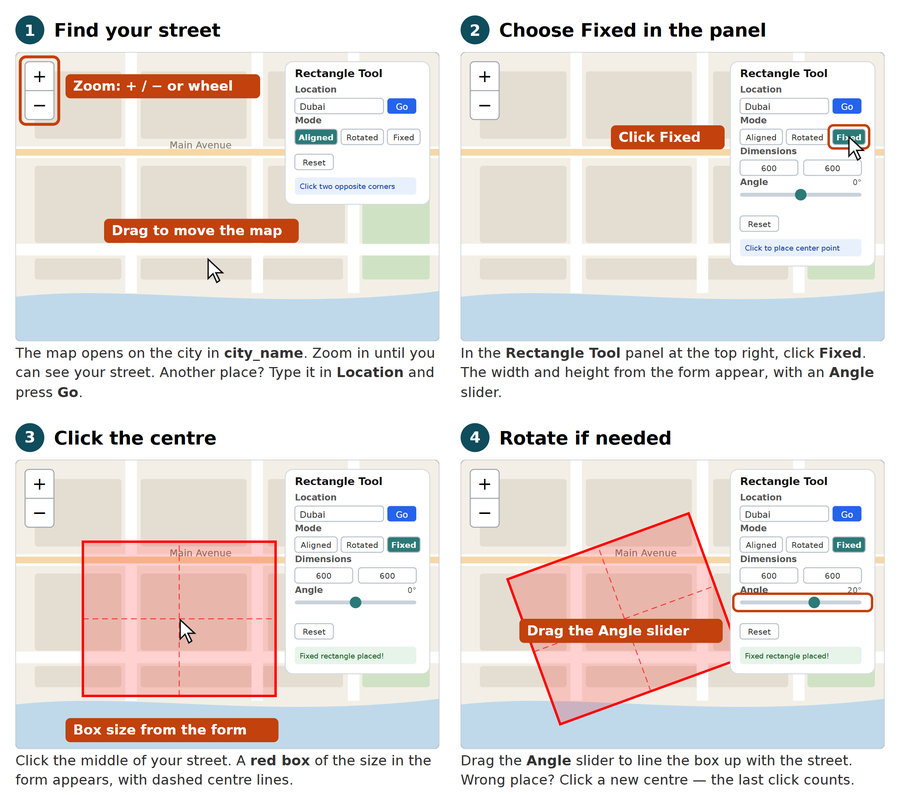

In [ ]:
#@title 2.1 Map for choosing the area { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
city_name = "Dubai"  #@param {type:"string"}
box_width_m = 600  #@param {type:"slider", min:300, max:1500, step:50}
box_height_m = 600  #@param {type:"slider", min:300, max:1500, step:50}
#@markdown ↑ Size of the area in metres.
choose_area(city_name, box_width_m, box_height_m)

## 3 · Build the 3D city
VoxCity downloads open data for your box — buildings, trees, land cover, terrain — and turns it into small cubes (*voxels*). Takes 1–5 minutes. If it fails, run it again.

In [ ]:
#@title 3.1 Build the 3D city { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
cell_size_m = 5  #@param {type:"slider", min:2, max:10, step:1}
#@markdown ↑ Size of one cube in metres (5 m is a good balance).
build_city(cell_size_m)

## 4 · Look at your city
Turn and zoom the 3D view. Do the building heights and the trees look right?

In [ ]:
#@title 4.1 3D view { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
show_3d()

**What to see:** each cube is one cell of the model. Buildings, trees and the ground come from open map data, so some may be missing or have the wrong height; a building with no height in the data gets a default height. The results are only as good as these data.

## 5 · Sunlight in the street
### 5.1 One moment
Sunlight at 1.5 m above the ground: bright = sun, dark = shade, grey = buildings. The weather is a **typical year** (an average of many years), so you choose a month and a day, not a date in a real year. Start with **21 June, 15:00**, then try other days and hours.

In [ ]:
#@title 5.1 Sunlight at one moment { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
month = "June"  #@param ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
day = 21  #@param {type:"slider", min:1, max:31, step:1}
#@markdown ↑ The weather is a typical year, so there is no year to choose.
hour = 15  #@param {type:"slider", min:5, max:20, step:1}
#@markdown ↑ Local time (15 = 3 pm).
sunlight(f"{day} {month}", hour)

**What to see:** the sun's height and direction are written above the map. Pick one building and find its shadow: the shade falls on the side away from the sun. Change the hour and run again to watch the shade move.

### 5.2 A whole year
The sunlight added up over a typical year, in **kWh/m² a year**. Parts 6–8 use this map.

In [ ]:
#@title 5.2 Sunlight over a typical year { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
yearly()

**What to see:** bright places get much sunlight over the year, dark places little. Compare with the map in 5.1: are the darkest places the same as the shade at 3 pm?

## 6 · Measure a walk
Run 6.1. The dashed line is your study area: draw the walk inside it.
1. Click the **line** tool on the left of the map.
2. Click point by point along the pavement — not the middle of the road.
3. Click the last point again to finish.
4. Run 6.2.

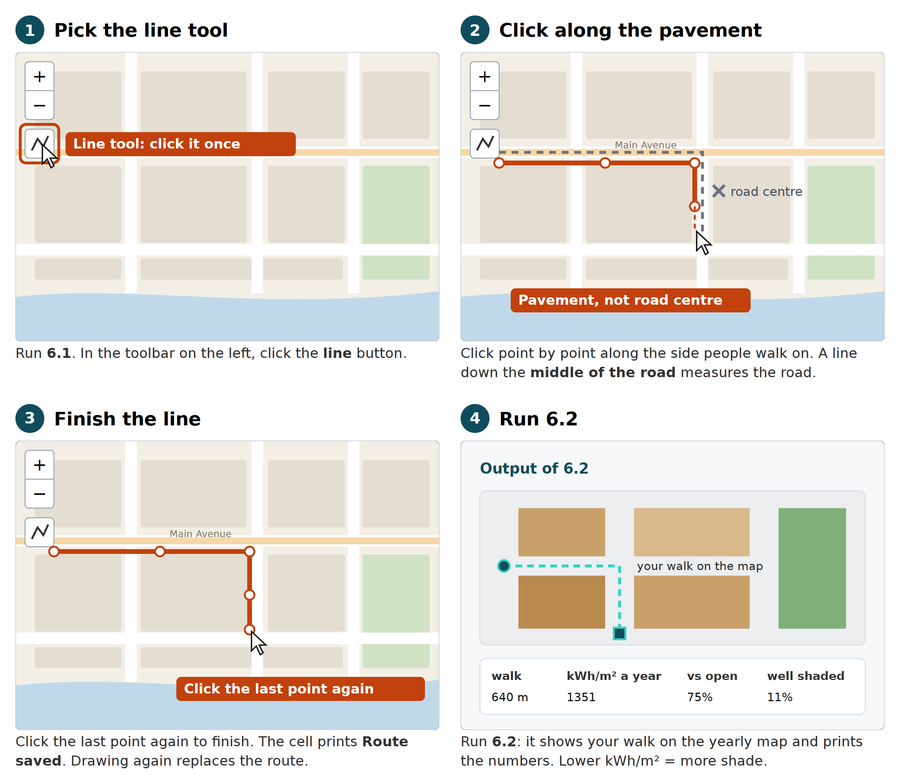

In [ ]:
#@title 6.1 Map for drawing a walk { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
draw_walk()

6.2 shows your walk on the yearly map. The key number is **sunlight on the walk** (kWh/m² a year): lower means more shade. The line chart shows where along the walk it is sunny (high) or shaded (low).

In [ ]:
#@title 6.2 Measure the walk { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
baseline()

## 7 · What if? Change one building or tree
Choose *Trees* or *Buildings* in 7.1 and run it. Add or remove one thing (press **+ Add** to add), then run 7.2 to see the effect, also on your walk.

**Buildings**

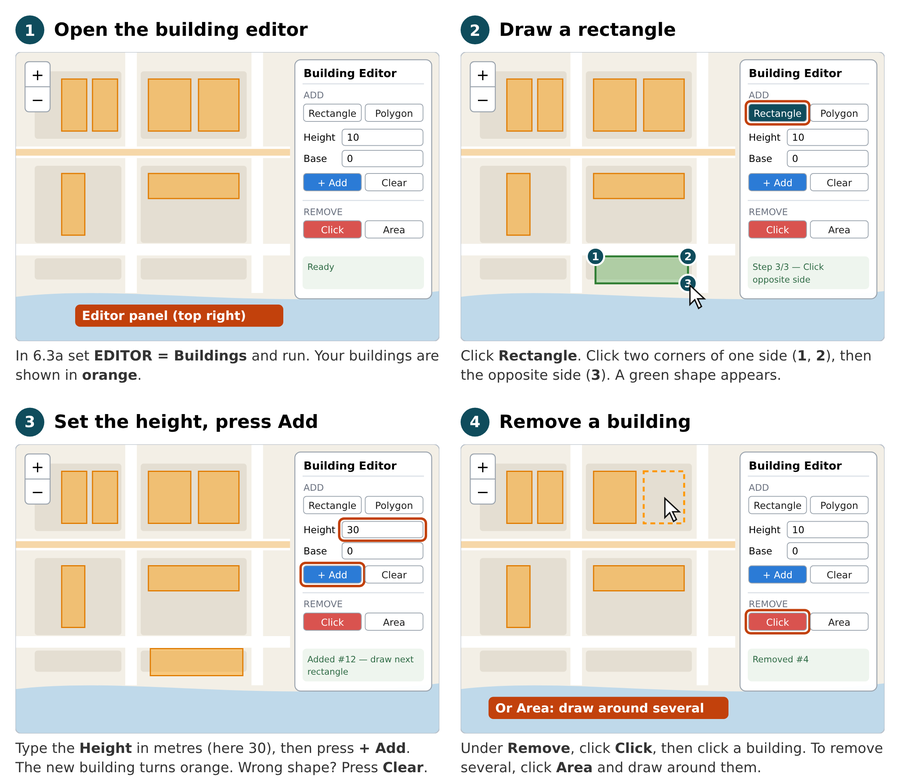

**Trees**

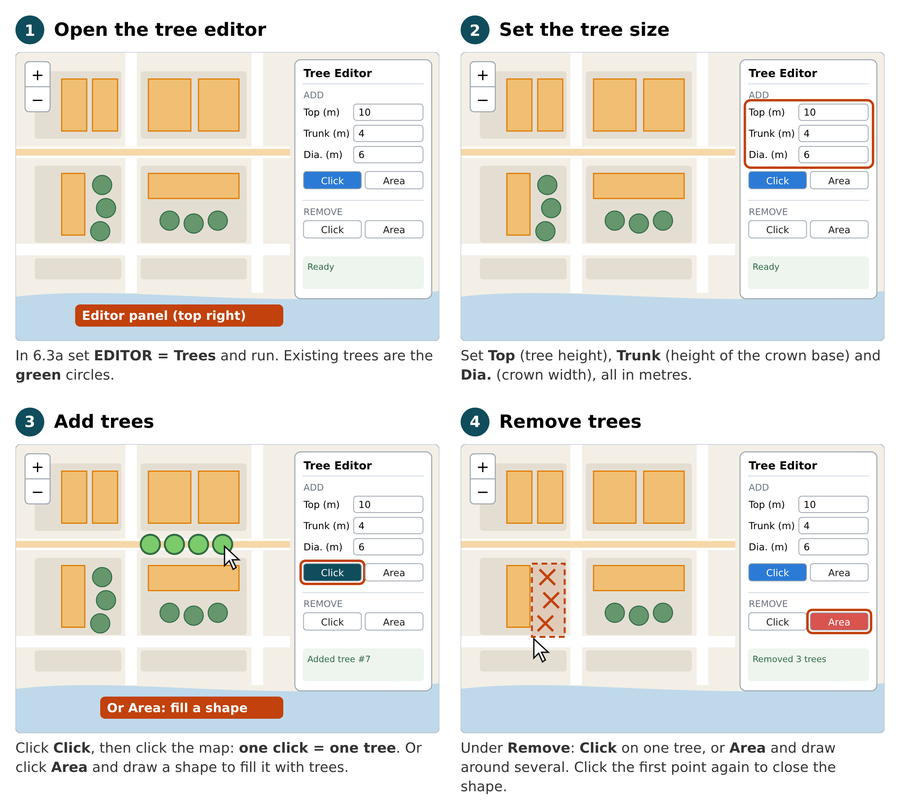

In [ ]:
#@title 7.1 Map editor { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
editor = "Trees"  #@param ["Trees", "Buildings"]
open_editor(editor)

In [ ]:
#@title 7.2 Show the effect of the change { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
what_if()

**What to see:** where the sunlight dropped, and how much it changed on your walk. The line chart shows where along the walk it changed. On which side of the tree or building did it drop most?

### Back to the two questions
1. **At 3 pm on 21 June** the sun is in the west, so shade falls to the east: the pavements on the east side of streets and buildings are in shade.
2. **Over a whole year** the least sunlight reaches places that see little open sky and lie on the side away from the midday sun: narrow streets, the north side of tall buildings, the ground under trees. (North of the tropics the midday sun is in the south.) This is not the same as the shade at 3 pm.

*Finished early? Try the **Extra** section at the end.*

---
# 8 · Competition: Shade the Walk
**A 470 m walk in a residential street in Dubai.** Everyone gets the same walk and the same **10 trees**. Place all 10 so that the walk gets the **least sunlight over a year**. The lowest score wins.

| Cell | What you do |
|---|---|
| **8.1** | Load the walk and its score without trees (once) |
| **8.2** | Place the trees |
| **8.3** | Score them — each score is kept as a design |
| **8.4** | Compare your designs |

Repeat 8.2 → 8.3 to improve.

### 8.1 Load the competition
Shows the walk, its score without trees and a profile: the high parts are sunny stretches where trees help most.

In [ ]:
#@title 8.1 Load the competition { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
# Competition settings: the same for everyone, so the scores can be compared.
COMPETITION = {'centre': '55.185685, 25.071132', 'width_m': 635, 'height_m': 635, 'walk': '55.185187,25.069962; 55.185187,25.070727; 55.185038,25.071267; 55.185088,25.071537; 55.184790,25.072167; 55.184939,25.072257; 55.185287,25.072302; 55.185685,25.072032; 55.185734,25.072077; 55.185933,25.071942; 55.186182,25.071897; 55.186579,25.071537', 'trees_available': 10, 'tree_height_m': 10, 'trunk_height_m': 3, 'crown_diameter_m': 8, 'model_url': ''}
competition(**COMPETITION, data=COMPETITION_DATA)

### 8.2 Place your trees
Under **Add**, click **Click**, then click the map: one click = one tree (only these trees count). To remove one: **Remove › Click**. The counter turns green at 10. To start from an earlier design, type its name in *start_from*.

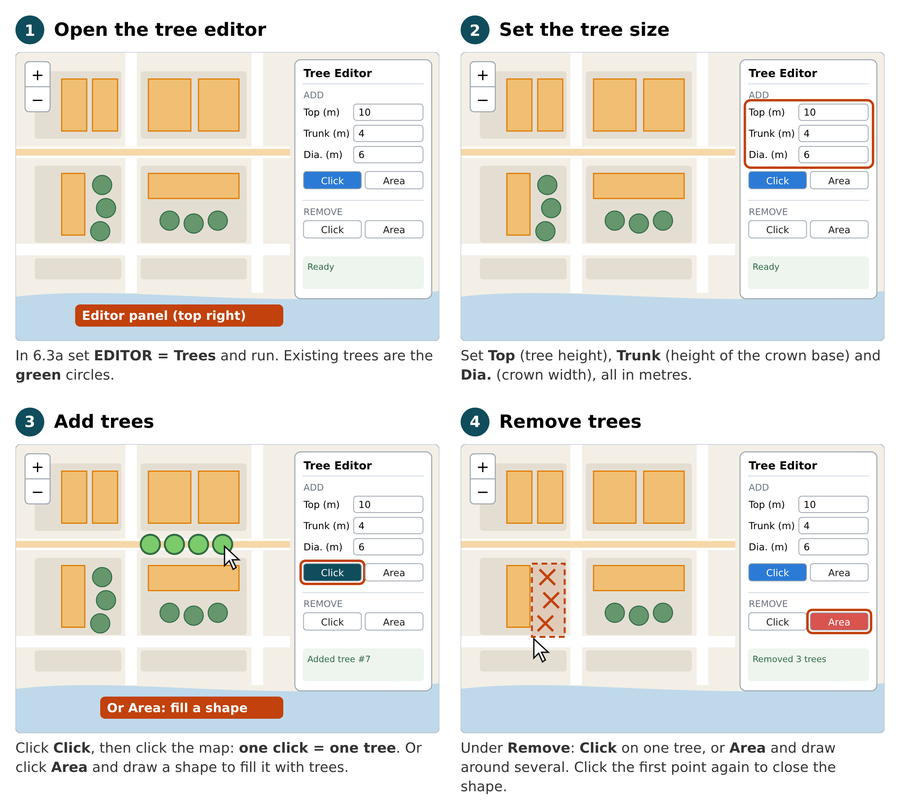

In [ ]:
#@title 8.2 Place your trees { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
start_from = ""  #@param {type:"string"}
#@markdown ↑ Empty, or the name of a design to start from.
place_trees(start_from)

### 8.3 Score the trees on the map
Shows the score and where the sunlight dropped. Then go back to 8.2, move trees and score again.

In [ ]:
#@title 8.3 Score the trees on the map { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
design_name = ""  #@param {type:"string"}
#@markdown ↑ Empty = design 1, design 2, …
score(design_name)

### 8.4 Compare your designs
All your designs, ranked. Where a profile is still high, move trees there.

In [ ]:
#@title 8.4 Compare your designs { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
compare_designs()

### 8.5 Bring back your designs (only after a time-out)
Run 1.1, 1.2 and 8.1 first. Then run this cell and choose the *trees_….csv* files, or the zip from 9.1.

In [ ]:
#@title 8.5 Restore designs from downloaded tree files { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
restore_designs()

## 9 · Save your results
Downloads your maps, ranking and tree files as one zip. The map shows sunlight and shade only — not air temperature, wind or humidity.

In [ ]:
#@title 9.1 Download results { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
download_results()

*VoxCity: Fujiwara et al. (2026), Computers, Environment and Urban Systems 123, 102366.*

---
## Extra
**E1** When during the day is the ground shaded? · **E2** How does one hour change over the year?

In [ ]:
#@title E1 · When during the day is the ground shaded? { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
#@markdown **Predict first:** on 21 June, at which hour is there the *least* shade?
my_prediction = ""  #@param {type:"string"}
first_month = "June"  #@param ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
first_day = 21  #@param {type:"slider", min:1, max:31, step:1}
second_month = "December"  #@param ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
second_day = 21  #@param {type:"slider", min:1, max:31, step:1}
#@markdown ↑ Two days of the typical year to compare.
extra_day(f"{first_day} {first_month}", f"{second_day} {second_month}", my_prediction)

In [ ]:
#@title E1 · Explain { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
my_explanation = ""  #@param {type:"string"}
#@markdown ↑ Why is the ground least shaded when the sun is highest?
print("Saved.")

In [ ]:
#@title E2 · How does one hour change over the year? { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
#@markdown **Predict first:** in which month is there the most shade at 3 pm? And the least?
my_prediction = ""  #@param {type:"string"}
hour = 15  #@param {type:"slider", min:6, max:19, step:1}
#@markdown ↑ Hour to follow through the year (15 = 3 pm).
extra_year(hour, my_prediction)

In [ ]:
#@title E2 · Explain { display-mode: "form" }
if "STATE" not in globals():   # Colab was restarted or timed out: the set-up from 1.2 is gone
    raise SystemExit("Colab was restarted or timed out, so everything was reset. Go to the top: run 1.1, then 1.2 (see “If Colab times out”). Then come back and run this cell again.")
my_explanation = ""  #@param {type:"string"}
#@markdown ↑ Why is there least shade around midsummer and most around December?
print("Saved.")